# Линейный дискриминантный анализ (ЛДА)

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt

подгрузка данных

In [2]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import seaborn as sns

In [4]:
data = sns.load_dataset ('titanic')
data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


Удаление повторяющихся признаков

In [5]:
data_new = data.drop(columns=["class","who","adult_male","deck","alive","embark_town"])

In [6]:
data_new

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True
...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,True
887,1,1,female,19.0,0,0,30.0000,S,True
888,0,3,female,NaN,1,2,23.4500,S,False
889,1,1,male,26.0,0,0,30.0000,C,True


подготовка данных

Проверка пустых значений

In [7]:
missing_counts = data_new.isnull().sum()

print(missing_counts)

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
alone         0
dtype: int64


Кодировка данных (перекодирование)

In [8]:
from sklearn.preprocessing import LabelEncoder
# Create a label encoder object
label_encoder = LabelEncoder()

data_new_c = data_new.copy()
# Transform the 'categories' column
data_new_c['sex'] = label_encoder.fit_transform(data_new_c['sex'].values)
data_new_c['embarked'] = label_encoder.fit_transform(data_new_c['embarked'].values)

data_new_c['alone'] = label_encoder.fit_transform(data_new_c['alone'].values)

data_new_c

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22.0,1,0,7.2500,2,0
1,1,1,0,38.0,1,0,71.2833,0,0
2,1,3,0,26.0,0,0,7.9250,2,1
3,1,1,0,35.0,1,0,53.1000,2,0
4,0,3,1,35.0,0,0,8.0500,2,1
...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,2,1
887,1,1,0,19.0,0,0,30.0000,2,1
888,0,3,0,NaN,1,2,23.4500,2,0
889,1,1,1,26.0,0,0,30.0000,0,1


Заполнение пропусков 

In [9]:
F = data_new_c.fillna(data_new_c.median())
F

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,1,22.0,1,0,7.2500,2,0
1,1,1,0,38.0,1,0,71.2833,0,0
2,1,3,0,26.0,0,0,7.9250,2,1
3,1,1,0,35.0,1,0,53.1000,2,0
4,0,3,1,35.0,0,0,8.0500,2,1
...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.0,0,0,13.0000,2,1
887,1,1,0,19.0,0,0,30.0000,2,1
888,0,3,0,28.0,1,2,23.4500,2,0
889,1,1,1,26.0,0,0,30.0000,0,1


In [10]:
X_titanic = F.drop('survived', axis=1).values
y_titanic = F['survived'].values

In [11]:
X_titanic

array([[ 3.    ,  1.    , 22.    , ...,  7.25  ,  2.    ,  0.    ],
       [ 1.    ,  0.    , 38.    , ..., 71.2833,  0.    ,  0.    ],
       [ 3.    ,  0.    , 26.    , ...,  7.925 ,  2.    ,  1.    ],
       ...,
       [ 3.    ,  0.    , 28.    , ..., 23.45  ,  2.    ,  0.    ],
       [ 1.    ,  1.    , 26.    , ..., 30.    ,  0.    ,  1.    ],
       [ 3.    ,  1.    , 32.    , ...,  7.75  ,  1.    ,  1.    ]],
      shape=(891, 8))

In [12]:
y_titanic

array([0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1,

Стандартизация признаков

In [13]:
scaler = StandardScaler()
X_titanic_scaled = scaler.fit_transform(X_titanic)

In [14]:
X_titanic_scaled

array([[ 0.82737724,  0.73769513, -0.56573646, ..., -0.50244517,
         0.58111394, -1.2316449 ],
       [-1.56610693, -1.35557354,  0.66386103, ...,  0.78684529,
        -1.93846038, -1.2316449 ],
       [ 0.82737724, -1.35557354, -0.25833709, ..., -0.48885426,
         0.58111394,  0.81192233],
       ...,
       [ 0.82737724, -1.35557354, -0.1046374 , ..., -0.17626324,
         0.58111394, -1.2316449 ],
       [-1.56610693,  0.73769513, -0.25833709, ..., -0.04438104,
        -1.93846038,  0.81192233],
       [ 0.82737724,  0.73769513,  0.20276197, ..., -0.49237783,
        -0.67867322,  0.81192233]], shape=(891, 8))

Разделение данных на тестовую и критическую выборки

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X_titanic_scaled, y_titanic, test_size=0.2, random_state=42)

Линейный дискриминантный анализ

In [16]:
X_train

array([[-1.56610693,  0.73769513,  1.24023486, ..., -0.07458307,
         0.58111394,  0.81192233],
       [-0.36936484,  0.73769513, -0.48888662, ..., -0.38667072,
         0.58111394,  0.81192233],
       [ 0.82737724,  0.73769513,  0.20276197, ..., -0.48885426,
         0.58111394,  0.81192233],
       ...,
       [ 0.82737724,  0.73769513,  0.89441056, ..., -0.36435545,
         0.58111394, -1.2316449 ],
       [-1.56610693, -1.35557354, -1.18053521, ...,  1.76774081,
         0.58111394, -1.2316449 ],
       [-1.56610693,  0.73769513, -0.6425863 , ...,  0.90773798,
         0.58111394, -1.2316449 ]], shape=(712, 8))

In [17]:
y_train

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0,

линейный дискриминантный анализ

In [18]:
lda = LinearDiscriminantAnalysis(n_components = 1) # for 1D projection
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

In [19]:
threshold = lda.intercept_[0] / lda.coef_[0][0] if lda.coef_[0][0] !=0 else 0

Классифицируем, используя порог, полученный с помощью модели

In [20]:
predictions = lda.predict(X_test)

Вычисление точности

In [21]:
accuracy = (predictions == y_test).mean()
print(f"Точность LDA на наборе данных о Титанике: {accuracy:.2f}")

Точность LDA на наборе данных о Титанике: 0.80


In [22]:
from sklearn.metrics import accuracy_score, classification_report

# Вычисление точности
accuracy = accuracy_score(y_test, predictions)
print(f"Точность LDA на наборе данных о Титанике: {accuracy:.2f}")

# Дополнительно можно получить более подробный отчет
print("\nПодробный отчет о классификации:")
print(classification_report(y_test, predictions))

Точность LDA на наборе данных о Титанике: 0.80

Подробный отчет о классификации:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       105
           1       0.80      0.70      0.75        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



Визуализация проекции ЛДА и график значимости признаков (коэффициентов)

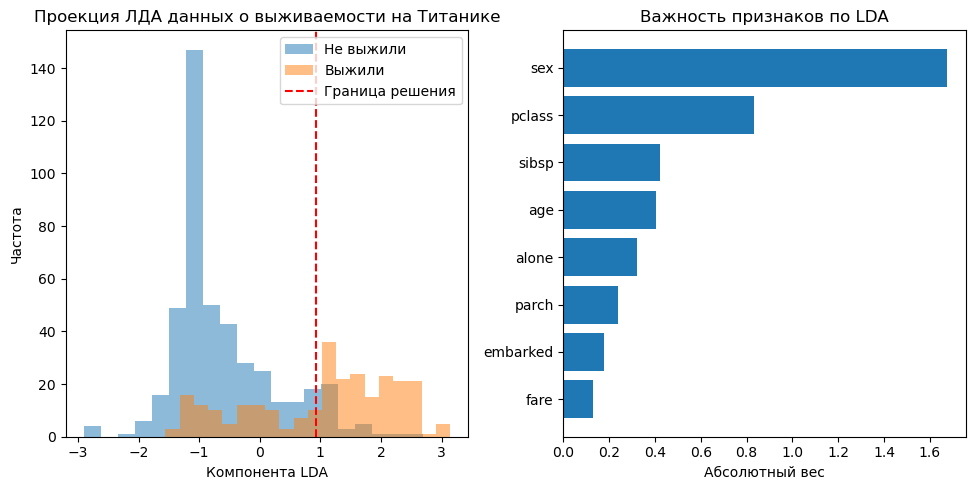

In [23]:
plt.figure(figsize=(10, 5))

# Визуализация проекции ЛДА
plt.subplot(121)
plt.hist(X_train_lda[y_train == 0], bins=20, alpha=0.5, label='Не выжили')
plt.hist(X_train_lda[y_train == 1], bins=20, alpha=0.5, label='Выжили')
plt.axvline(threshold, color='r', linestyle='--', label='Граница решения')
plt.xlabel('Компонента LDA')
plt.ylabel('Частота')
plt.legend()
plt.title('Проекция ЛДА данных о выживаемости на Титанике')

# График значимости признаков (коэффициентов)
plt.subplot(122)
feature_importance = abs(lda.coef_[0])
feature_names = data_new.drop(columns = ['survived']).columns
sorted_idx = feature_importance.argsort()
pos = np.arange(sorted_idx.shape[0]) + .5
plt.barh(pos, feature_importance[sorted_idx], align='center')
plt.yticks(pos, feature_names[sorted_idx])
plt.xlabel('Абсолютный вес')
plt.title('Важность признаков по LDA')

plt.tight_layout()
plt.show()

При выволнении практической работы 8, первым делом были подргужены данные "Титаник", для проведелия линейного дискриминантного анализа (Анализа влияния каждого отдельного признака на выживание пасссажиров Титаника). На этапе преобработки мы удалили повторяющиеся стоблцы датафрейма, проверили наличие пропущенных значений в данных и выяснили, что они составляют 20%, соответвенно удалить их не можем и будем заполнять с помощью медианных значений. Перед заполнением пропусков необходимо было провести кодировку качественных признаков в данных, что мы и сделали с помощью LabelEncoding. Далее были заполнены пропуски, а также обработанные данные были разделены на результативный и факторные признаки. Далее была проведена стандартизация данных и они были разделены на тестовую и обучающую выборки. Следующим этапом мы выполнили дискриминантный анализ и определили пороговое значение для классификации. Далее мы проводим классификацию на основе порогового значения (выжили/невыжили) и вычисляем точность модели - 0.8, что говорит о том, что модель достаточно точно классифицировала признаки влияющие на выживаемость, также был получен более подробный отчет для анализа точности. Последним этапом были визуализированы результаты проведенного дискриминантного анализа. Был получин график проекции ЛДА данных о выживаемости на Титанике, где граница решения достаточно точно разделяет события выжил/невыжил, что также говорит о точности модели. Также была получена гистограмма отражаюая важность признаков, влияющих на выживаемость на Титанике. Как можно заметить на диаграмме наиболее важным ( имеющим влияние) является пол (sex), вторым по влиянию является класс (pclass) и третьим число родственников на борту (sibsp). Таким образом можно сделать вывод о том, что на выживаемость пассажиров больше всего повлиял пол, в каком классе они находились, а также количество родственником, которые также были на судне.